# Corporate Churn Early-Warning: walkthrough

This notebook runs the whole pipeline on **synthetic data** and explains each decision.
The original system was built for a corporate bulk-payments platform at a commercial bank. No real client data is used here.

**Question:** which corporate clients will go dormant in the next ~90 days, when, and why?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import subprocess, sys, pandas as pd, numpy as np
from pathlib import Path
from IPython.display import Image, display
subprocess.run([sys.executable, "data/generate_synthetic.py"], check=True)
from src.features import connect, build_model_base, to_matrix
from src.select_features import vif_reduce, vif_table
from src.models import train_xgb, train_cox, tier_report, gini
con = connect()
con.execute("SELECT direction, COUNT(*) rows, SUM(txn_count) txns FROM payments_weekly GROUP BY 1").df()

clients: 3,000 rows  |  payments_weekly: 349,503 rows  ->  /home/claude/repos/corporate-churn-survival/data/raw


,direction,rows,txns
0,IN,175018,3868904.0
1,OUT,174485,5604044.0


## 1. Defining churn honestly

A client that stops *sending* payments but keeps *receiving* them is still a live relationship.
So **authentic churn** means dormancy in **both** directions: no outbound and no inbound activity in the last 8 weeks of a 13-week (~90-day) outcome window.

The scoring population is clients who were still active in the last 4 weeks before the snapshot. Clients who have already gone quiet are a recovery problem, not a retention one.

In [2]:
train = build_model_base(con, snapshot=52)   # training snapshot
oot   = build_model_base(con, snapshot=65)   # out-of-time snapshot, 13 weeks later
pd.DataFrame({"clients": [len(train), len(oot)],
              "churn_rate": [train.churn_flag.mean(), oot.churn_flag.mean()]},
             index=["train (wk 52)", "OOT (wk 65)"]).round(3)

,clients,churn_rate
train (wk 52),2057,0.062
OOT (wk 65),1876,0.052


## 2. Features: RFM + trend, built in SQL
All features come from `sql/02_rfm_features.sql` and `sql/03_trend_features.sql`, run in DuckDB. A dense client-by-week grid makes sure silent weeks count as zeros when computing slopes and trends.

In [3]:
train.drop(columns=['client_id']).describe().T[['mean','std','min','max']].round(2)

,mean,std,min,max
snapshot_week,52.00,0.00,52.00,52.00
churn_flag,0.06,0.24,0.00,1.00
surv_event,0.15,0.36,0.00,1.00
surv_duration_weeks,23.34,6.79,1.00,26.00
tenure_months,62.38,33.11,15.00,252.00
products_held,2.81,1.70,1.00,9.00
has_rm,0.71,0.45,0.00,1.00
recency_out_wks,1.34,1.83,1.00,14.00
recency_in_wks,1.08,0.53,1.00,14.00
freq_out,383.03,421.45,0.00,3521.00


## 3. Removing multicollinearity with VIF
Correlated RFM features inflate each other and make the explanations unstable, so features are dropped one at a time until every VIF is below 5.

In [4]:
X = to_matrix(train)
features, dropped = vif_reduce(X, threshold=5.0)
print(f"{X.shape[1]} candidate features -> {len(features)} kept")
pd.DataFrame(dropped, columns=["dropped_feature", "vif_when_dropped"]).round(1)

21 candidate features -> 18 kept


,dropped_feature,vif_when_dropped
0,recency_out_wks,13.0
1,log_monetary_out,6.6
2,trend_out_cnt,5.6


## 4. Who will churn: XGBoost, validated out of time
The model is trained on the week-52 snapshot and tested on the week-65 snapshot, which it never saw. This is the honest test of whether it would work next quarter.

In [5]:
from sklearn.metrics import roc_auc_score
model, auc_val = train_xgb(X[features], train.churn_flag)
X_oot = to_matrix(oot).reindex(columns=features, fill_value=0.0)
p_oot = model.predict_proba(X_oot)[:, 1]
auc_oot = roc_auc_score(oot.churn_flag, p_oot)
print(f"ROC-AUC  validation: {auc_val:.3f}   out-of-time: {auc_oot:.3f}   (Gini {gini(auc_oot):.3f})")

ROC-AUC  validation: 0.856   out-of-time: 0.844   (Gini 0.688)


## 5. Turning scores into actions: two risk tiers
The relationship team cannot call everyone. **High ≥ 0.55** goes to immediate RM outreach and **Medium 0.35–0.55** to a lighter-touch campaign.

In [6]:
tier_report(oot.churn_flag, p_oot, high=0.55, medium=0.35)

,clients,churners,churn_rate,share_of_churners,lift_vs_base
tier,,,,,
HIGH,245,60,0.245,0.612,4.688
MEDIUM,357,15,0.042,0.153,0.804
LOW,1274,23,0.018,0.235,0.346


## 6. Why: SHAP explanations

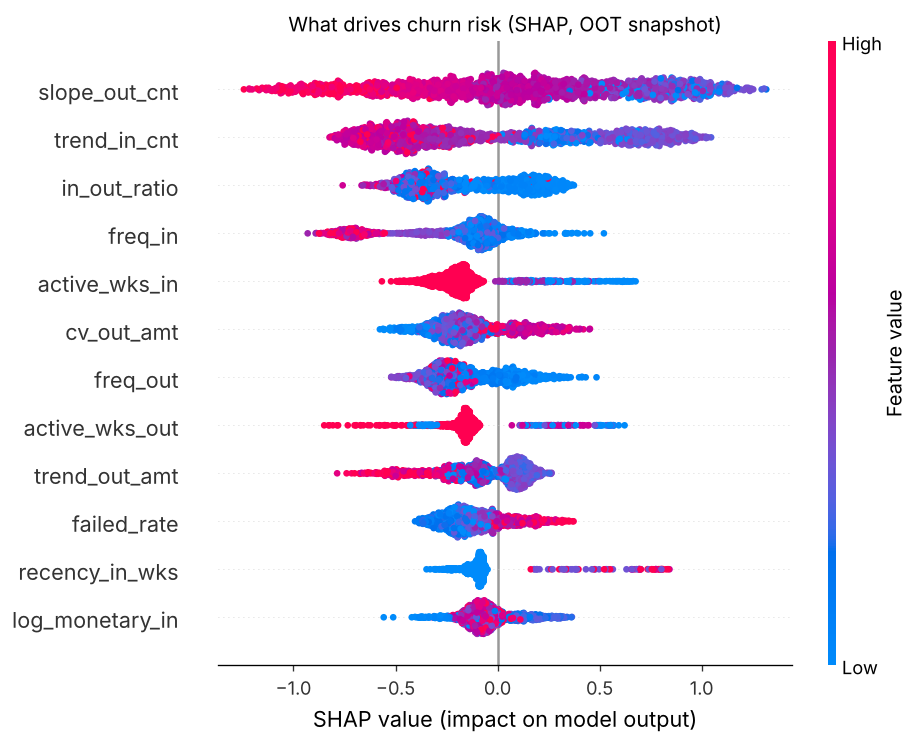

In [7]:
import subprocess, sys
subprocess.run([sys.executable, "run_pipeline.py"], check=True, capture_output=True)
display(Image("reports/figures/shap_summary.png", width=640))

Falling outbound volume (`slope_out_cnt`) and falling inbound activity (`trend_in_cnt`) dominate. These are the *fade* signals that show up before a client leaves. Payment failures (`failed_rate`) add risk, which points to a service-quality fix and not only a sales fix.

## 7. When: Cox proportional hazards
The classifier answers *who*. The survival model answers *how soon*, which sets the order of the outreach queue.

,covariate,hazard_ratio_per_sd,p
0,failed_rate,1.264,0.000
1,recency_in_wks,1.110,0.000
2,log_monetary_in,1.087,0.150
3,seg_SME,1.084,0.192
4,seg_PUBLIC_SECTOR,1.022,0.682
5,active_wks_out,1.013,0.821
6,cv_out_amt,0.976,0.616
7,freq_out,0.939,0.351


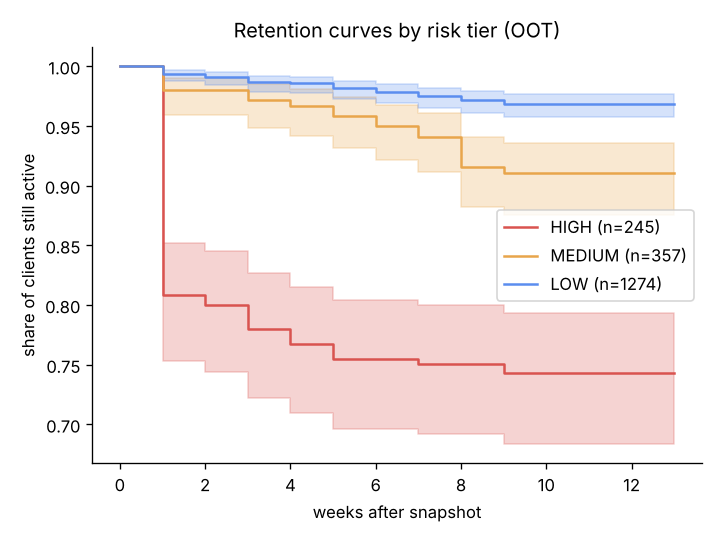

In [8]:
display(pd.read_csv("reports/cox_hazard_ratios.csv").head(8))
display(Image("reports/figures/km_by_tier.png", width=560))

The risk tiers also separate clearly on time-to-churn, so the High tier is where the urgency is.

## 8. Output
Each client gets a score, a tier and its top three reasons, ready for a customer-360 view or CRM.

In [9]:
pd.read_csv('reports/scored_clients_oot.csv').head(10)

,client_id,segment,risk_score,risk_tier,top_reasons
0,C100635,LARGE_CORPORATE,0.9766,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
1,C101916,SME,0.9760,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
2,C102536,SME,0.9753,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
3,C100390,SME,0.9746,HIGH,"slope_out_cnt, recency_in_wks, active_wks_in"
4,C101418,SME,0.9744,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
5,C100333,SME,0.9736,HIGH,"slope_out_cnt, recency_in_wks, active_wks_in"
6,C100177,PUBLIC_SECTOR,0.9728,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
7,C102921,LARGE_CORPORATE,0.9726,HIGH,"slope_out_cnt, recency_in_wks, active_wks_in"
8,C100162,COMMERCIAL,0.9720,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
9,C102259,COMMERCIAL,0.9712,HIGH,"slope_out_cnt, recency_in_wks, trend_in_cnt"
